In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
CSV_PATH = None            # e.g. "housing.csv"
TARGET = "MedHouseVal"     # median house value, in units of $100,000

if CSV_PATH:
    df = pd.read_csv(CSV_PATH)
    source = f"CSV file: {CSV_PATH}"
else:
    try:
        df = fetch_california_housing(as_frame=True).frame
        source = "California Housing (scikit-learn)"
    except Exception:
        rng = np.random.default_rng(RANDOM_STATE)
        n = 6000
        d = pd.DataFrame({
            "MedInc": rng.lognormal(1.2, 0.5, n).clip(0.5, 15),
            "HouseAge": rng.integers(1, 53, n).astype(float),
            "AveRooms": 4 + rng.lognormal(0.5, 0.5, n),
            "Population": rng.lognormal(7, 0.7, n).clip(3, 35000),
            "AveOccup": 1.5 + rng.lognormal(0.7, 0.4, n),
            "Latitude": rng.uniform(32.5, 42, n),
            "Longitude": rng.uniform(-124.3, -114.3, n),
        })
        d["AveBedrms"] = d["AveRooms"] * rng.uniform(0.15, 0.3, n)
        d[TARGET] = (0.45 * d["MedInc"] + 0.008 * d["HouseAge"] + 0.04 * d["AveRooms"]
                     - 0.15 * d["AveOccup"] - 0.05 * (d["Latitude"] - 37)
                     + rng.normal(0, 0.45, n)).clip(0.15, 5) + 1.2
        df = d
        source = "SYNTHETIC fallback (download unavailable)"

print("Data source:", source)
print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
df.head()

Data source: California Housing (scikit-learn)
Shape: (20640, 9)
Missing values: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


               count      mean       std      min      25%       50%       75%        max
MedInc       20640.0     3.871     1.900    0.500    2.563     3.535     4.743     15.000
HouseAge     20640.0    28.639    12.586    1.000   18.000    29.000    37.000     52.000
AveRooms     20640.0     5.429     2.474    0.846    4.441     5.229     6.052    141.909
AveBedrms    20640.0     1.097     0.474    0.333    1.006     1.049     1.100     34.067
Population   20640.0  1425.477  1132.462    3.000  787.000  1166.000  1725.000  35682.000
AveOccup     20640.0     3.071    10.386    0.692    2.430     2.818     3.282   1243.333
Latitude     20640.0    35.632     2.136   32.540   33.930    34.260    37.710     41.950
Longitude    20640.0  -119.570     2.004 -124.350 -121.800  -118.490  -118.010   -114.310
MedHouseVal  20640.0     2.069     1.154    0.150    1.196     1.797     2.647      5.000


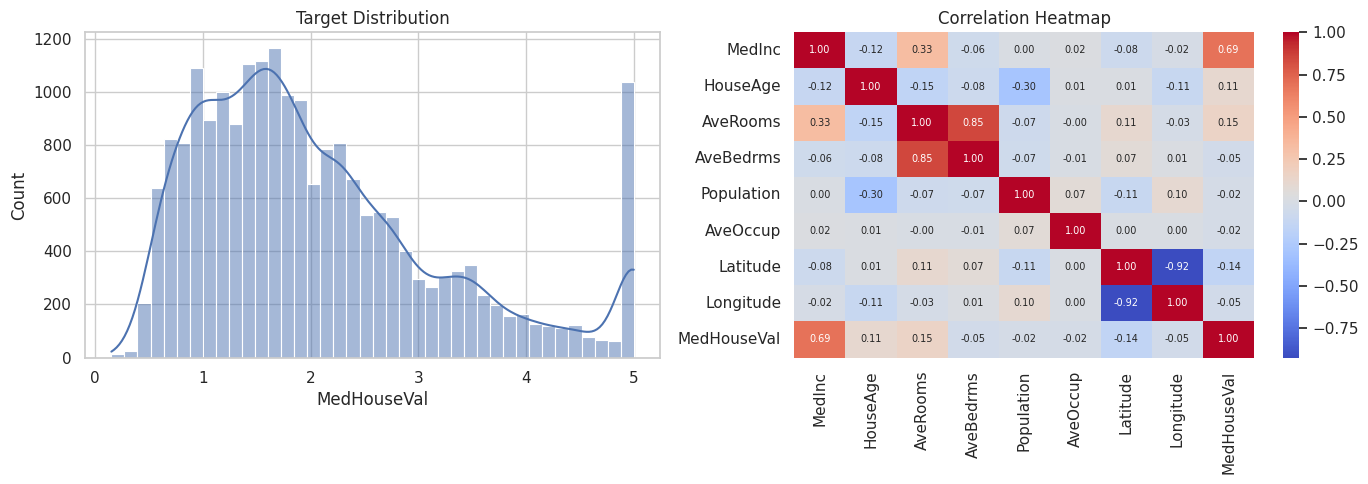

In [3]:
print(df.describe().T.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df[TARGET], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Target Distribution")
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1], annot_kws={"size": 7})
axes[1].set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [4]:
X_raw = df.drop(columns=TARGET)
y = df[TARGET]

Xtr_raw, Xte_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Train:", Xtr_raw.shape, "| Test:", Xte_raw.shape)

Train: (16512, 8) | Test: (4128, 8)


In [5]:
cap_cols = [c for c in ["AveRooms", "AveBedrms", "AveOccup", "Population"] if c in Xtr_raw.columns]
caps = {c: Xtr_raw[c].quantile(0.99) for c in cap_cols}   # learned from training data only

def engineer(X):
    X = X.copy()
    for c, cap in caps.items():
        X[c] = X[c].clip(upper=cap)
    X["bedroom_ratio"] = X["AveBedrms"] / X["AveRooms"]
    X["rooms_per_person"] = X["AveRooms"] / X["AveOccup"]
    X["log_population"] = np.log1p(X["Population"])
    X["income_squared"] = X["MedInc"] ** 2
    X["income_x_age"] = X["MedInc"] * X["HouseAge"]
    return X

X_train_fe = engineer(Xtr_raw)
X_test_fe = engineer(Xte_raw)
print("Features before:", Xtr_raw.shape[1], "| after:", X_train_fe.shape[1])
print(list(X_train_fe.columns))


Features before: 8 | after: 13
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'bedroom_ratio', 'rooms_per_person', 'log_population', 'income_squared', 'income_x_age']


In [6]:
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_fe), columns=X_train_fe.columns, index=X_train_fe.index)
X_test = pd.DataFrame(scaler.transform(X_test_fe), columns=X_test_fe.columns, index=X_test_fe.index)

# Scaled raw features (no engineering) for a fair comparison
scaler_raw = StandardScaler()
Xtr_raw_s = scaler_raw.fit_transform(Xtr_raw)
Xte_raw_s = scaler_raw.transform(Xte_raw)

In [7]:
def evaluate(name, model, Xtr, Xte):
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    return {
        "Model": name,
        "Train R2": r2_score(y_train, p_tr),
        "Test R2": r2_score(y_test, p_te),
        "Test MAE": mean_absolute_error(y_test, p_te),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, p_te)),
    }

lin_raw = LinearRegression().fit(Xtr_raw_s, y_train)
lin_fe = LinearRegression().fit(X_train, y_train)
ridge = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(X_train, y_train)
lasso = LassoCV(alphas=np.logspace(-4, 0, 50), cv=5, max_iter=20000, random_state=RANDOM_STATE).fit(X_train, y_train)

print("Best Ridge alpha:", round(ridge.alpha_, 4))
print("Best Lasso alpha:", round(lasso.alpha_, 5))

Best Ridge alpha: 14.5635
Best Lasso alpha: 0.00066


                                  Train R2  Test R2  Test MAE  Test RMSE
Model                                                                   
Linear Regression (raw features)    0.6126   0.5758    0.5332     0.7456
Linear Regression (engineered)      0.6841   0.6656    0.4801     0.6620
Ridge (engineered)                  0.6841   0.6656    0.4799     0.6620
Lasso (engineered)                  0.6841   0.6656    0.4800     0.6620


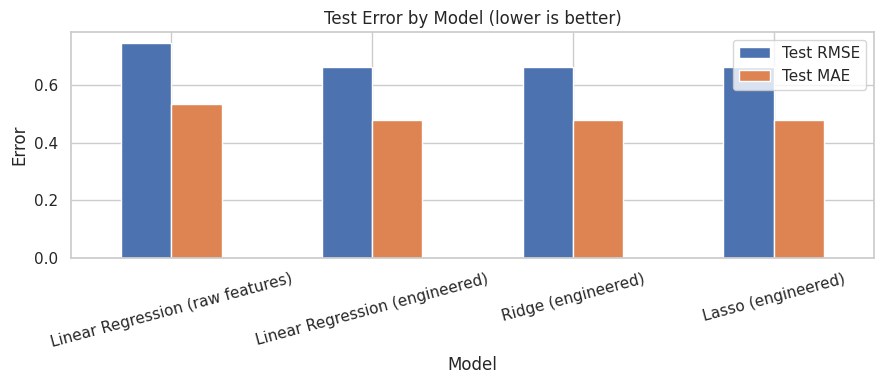

In [8]:
results = pd.DataFrame([
    evaluate("Linear Regression (raw features)", lin_raw, Xtr_raw_s, Xte_raw_s),
    evaluate("Linear Regression (engineered)", lin_fe, X_train, X_test),
    evaluate("Ridge (engineered)", ridge, X_train, X_test),
    evaluate("Lasso (engineered)", lasso, X_train, X_test),
]).set_index("Model").round(4)
print(results.to_string())

results[["Test RMSE", "Test MAE"]].plot(kind="bar", figsize=(9, 4), rot=15)
plt.title("Test Error by Model (lower is better)")
plt.ylabel("Error")
plt.tight_layout()
plt.show()


Analysing: Ridge
Mean residual: 0.0089 | Std: 0.6619 | Skew: 0.900


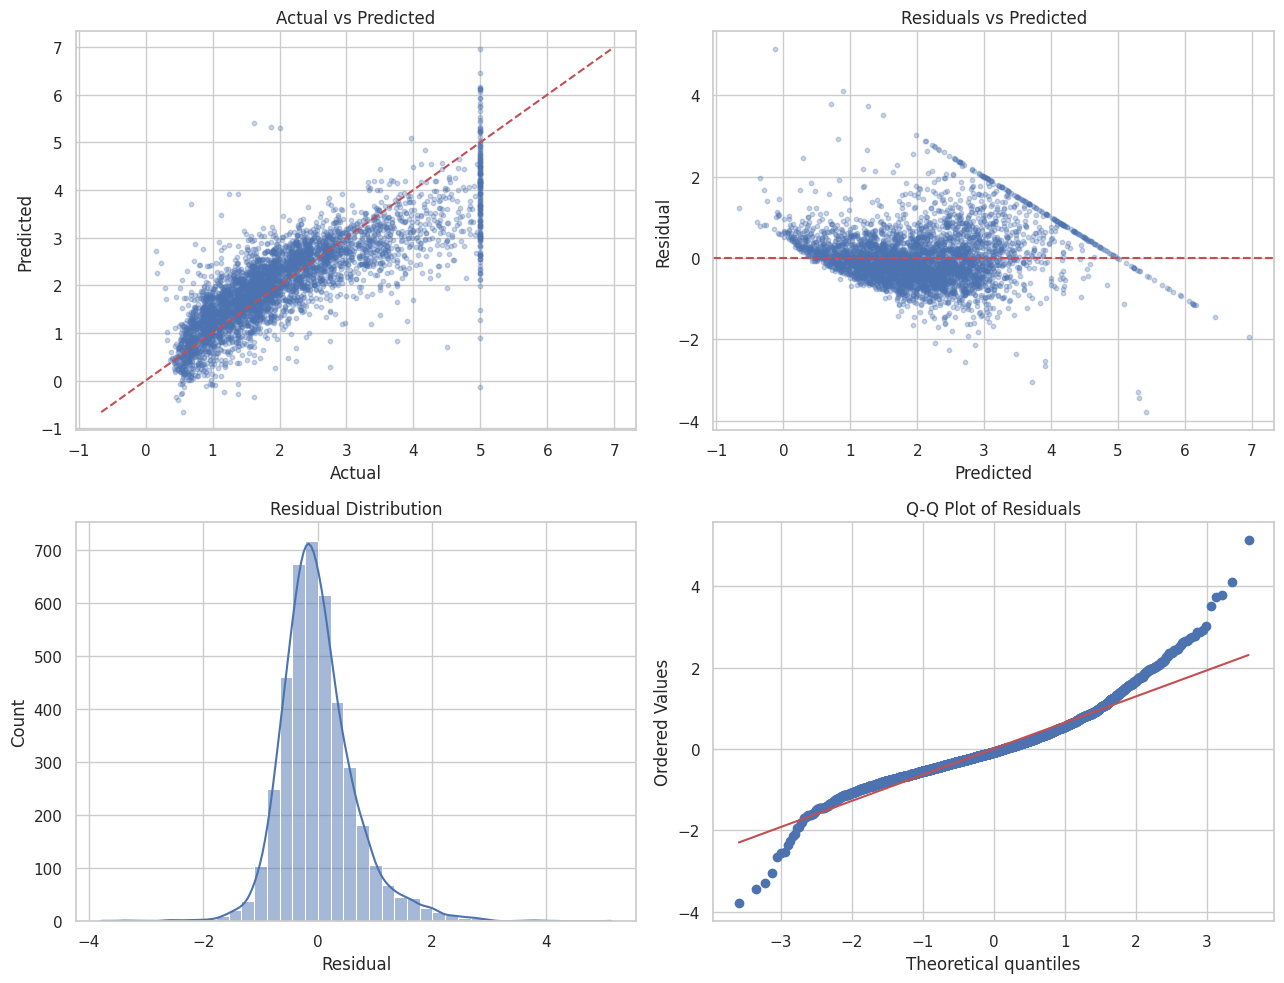

In [9]:
best_name, best_model = min(
    [("Ridge", ridge), ("Lasso", lasso)],
    key=lambda t: np.sqrt(mean_squared_error(y_test, t[1].predict(X_test)))
)
pred = best_model.predict(X_test)
resid = y_test.values - pred
print("Analysing:", best_name)
print(f"Mean residual: {resid.mean():.4f} | Std: {resid.std():.4f} | Skew: {stats.skew(resid):.3f}")

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].scatter(y_test, pred, alpha=0.3, s=10)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0, 0].plot(lims, lims, "r--")
axes[0, 0].set_title("Actual vs Predicted")
axes[0, 0].set_xlabel("Actual")
axes[0, 0].set_ylabel("Predicted")

axes[0, 1].scatter(pred, resid, alpha=0.3, s=10)
axes[0, 1].axhline(0, color="r", ls="--")
axes[0, 1].set_title("Residuals vs Predicted")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Residual")

sns.histplot(resid, bins=40, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Residual Distribution")
axes[1, 0].set_xlabel("Residual")

stats.probplot(resid, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q Plot of Residuals")

plt.tight_layout()
plt.show()

In [10]:
abs_corr = np.corrcoef(pred, np.abs(resid))[0, 1]
big_err = (np.abs(resid) > 2 * resid.std()).mean()

print(f"Correlation between |residual| and prediction: {abs_corr:.3f}")
print(f"Share of predictions with error > 2 standard deviations: {big_err:.2%}")
print()
print("How to read the plots:")
print("- Residuals centred on 0 with no pattern in the residual-vs-predicted plot -> a good linear fit.")
print("- A funnel shape (errors growing with the prediction) -> heteroscedasticity; consider a log-transform of the target.")
print("- Q-Q points bending away from the line at the ends -> heavy tails / outliers (e.g. capped house prices).")


Correlation between |residual| and prediction: 0.232
Share of predictions with error > 2 standard deviations: 5.23%

How to read the plots:
- Residuals centred on 0 with no pattern in the residual-vs-predicted plot -> a good linear fit.
- A funnel shape (errors growing with the prediction) -> heteroscedasticity; consider a log-transform of the target.
- Q-Q points bending away from the line at the ends -> heavy tails / outliers (e.g. capped house prices).
